# 02 — Módulo baseado em regras (K01–K08)
Objetivo: implementar o 'manual do técnico' como sistema de regras com **explicação do raciocínio** e avaliá-lo. Isto cobre o conteúdo de sistemas baseados em conhecimento e é a primeira das 3 abordagens a comparar (regras / ML / híbrido).

In [1]:
import sys; sys.path.insert(0, '..')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import precision_score, recall_score, f1_score
from src.dados import carregar_leituras
from src.regras import REGRAS, aplicar_regras, explicar

df = carregar_leituras()
r = aplicar_regras(df)          # com K08 ativo
r.head()

,K01,K02,K03,K04,K05,K06,K07,k08_pico,alarme
0,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False


## 1. Quantas vezes dispara cada regra?
Uma regra que dispara muito mas acerta pouco gera falsos alarmes; uma que nunca dispara (como a K07) é inútil nestes dados.

In [2]:
r[list(REGRAS) + ['k08_pico', 'alarme']].sum().to_frame('disparos')

,disparos
K01,22
K02,58
K03,14
K04,81
K05,430
K06,30
K07,0
k08_pico,41
alarme,579


## 2. Exemplo de explicação (interpretabilidade)
A grande vantagem das regras: sabemos **porquê** houve alarme.

In [3]:
for i in df.index[(r.alarme) & (df.falha == 1)][:3]:
    print(explicar(df, r, i), '| falha real:', df.loc[i, 'tipo_falha'], '\n')

ALARME na leitura L00051 (MQ01):
  - K05: Desgaste da ferramenta > 200 min -> Ferramenta perto do fim de vida | falha real: TWF 

ALARME na leitura L00067 (MQ01):
  - K04: Potência < 3500 W ou > 9000 W -> Potência fora da janela de operação | falha real: PWF 

ALARME na leitura L00071 (MQ01):
  - K04: Potência < 3500 W ou > 9000 W -> Potência fora da janela de operação | falha real: PWF 



## 3. Avaliação de cada regra e do conjunto
Duas tarefas: detetar a falha **na própria leitura** (`falha`) e **antecipar** (`falha_nas_proximas_24h`).

In [4]:
def avaliar(pred, alvo):
    return dict(precisao=precision_score(alvo, pred, zero_division=0),
                recall=recall_score(alvo, pred, zero_division=0),
                F1=f1_score(alvo, pred, zero_division=0),
                alarmes=int(pred.sum()))

linhas = []
for nome in list(REGRAS) + ['alarme']:
    for alvo in ['falha', 'falha_nas_proximas_24h']:
        linhas.append(dict(regra=nome, alvo=alvo, **avaliar(r[nome], df[alvo])))
res = pd.DataFrame(linhas).round(3)
res.pivot(index='regra', columns='alvo')

precisao                        recall                            F1  \
alvo      falha falha_nas_proximas_24h  falha falha_nas_proximas_24h  falha   
regra                                                                         
K01       0.364                  0.727  0.057                  0.006  0.099   
K02       0.328                  0.914  0.136                  0.021  0.192   
K03       0.714                  0.643  0.071                  0.003  0.130   
K04       0.383                  0.457  0.221                  0.014  0.281   
K05       0.181                  0.874  0.557                  0.145  0.274   
K06       0.833                  0.333  0.179                  0.004  0.294   
K07       0.000                  0.000  0.000                  0.000  0.000   
alarme    0.226                  0.808  0.936                  0.181  0.364   

                              alarmes                         
alvo   falha_nas_proximas_24h   falha falha_nas_proximas_24h  
regra                                                         
K01                     0.012      22                     22  
K02                     0.040      58                     58  
K03                     0.007      14                     14  
K04                     0.028      81                     81  
K05                     0.249     430                    430  
K06                     0.008      30                     30  
K07                     0.000       0                      0  
alarme                  0.296     579                    579

## 4. Que tipos de falha as regras apanham?
O manual é 'imperfeito de propósito': deve falhar as falhas aleatórias (RNF) e talvez outras.

In [5]:
falhas = df[df.falha == 1]
rec = (r.loc[falhas.index, 'alarme']).groupby(falhas.tipo_falha).agg(['sum', 'count'])
rec.columns = ['apanhadas', 'total']; rec['recall'] = (rec.apanhadas / rec.total).round(2)
rec

,apanhadas,total,recall
tipo_falha,,,
BRG,18,22,0.82
HDF,10,10,1.00
OSF,17,17,1.00
PWF,24,24,1.00
RNF,0,4,0.00
TWF,62,63,0.98


## 5. Falsos alarmes e picos de sensor: o que faz o K08?
Compara o sistema **com** e **sem** K08 (só ele muda: as regras de vibração K01/K02).

In [6]:
sem = aplicar_regras(df, usar_k08=False)
for nome, rr in [('sem K08', sem), ('com K08', r)]:
    fa = (rr.alarme & (df.falha == 0))
    print(f'{nome}: alarmes={rr.alarme.sum()}, falsos alarmes={fa.sum()}, '
          f'falsos alarmes em picos de sensor={(fa & df.leitura_anomala_sensor).sum()}, '
          f'F1(falha)={f1_score(df.falha, rr.alarme):.3f}')
print('Picos reais:', df.leitura_anomala_sensor.sum(), '| K08 deteta:', r.k08_pico.sum(),
      '| acertos do K08:', (r.k08_pico & df.leitura_anomala_sensor).sum())

sem K08: alarmes=614, falsos alarmes=483, falsos alarmes em picos de sensor=48, F1(falha)=0.347
com K08: alarmes=579, falsos alarmes=448, falsos alarmes em picos de sensor=13, F1(falha)=0.364
Picos reais: 49 | K08 deteta: 41 | acertos do K08: 41


## 6. Falsos alarmes por regra (quem faz mais barulho?)

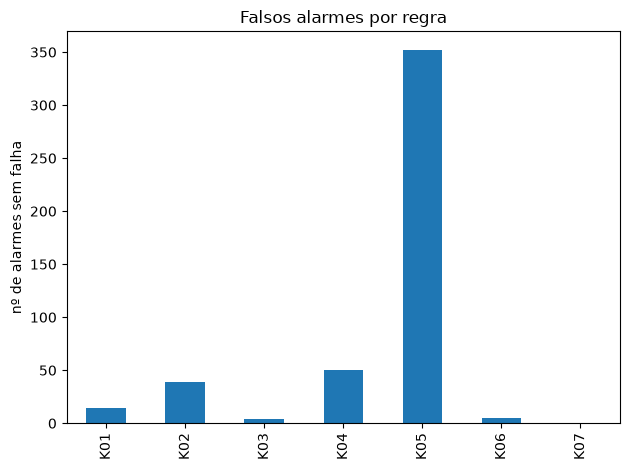

In [7]:
fa_por_regra = {k: int((r[k] & (df.falha == 0)).sum()) for k in REGRAS}
pd.Series(fa_por_regra).plot.bar(title='Falsos alarmes por regra'); plt.ylabel('nº de alarmes sem falha')
plt.tight_layout(); plt.savefig('../figuras/falsos_alarmes_por_regra.png', dpi=150); plt.show()

## Conclusões do Passo 2 

Os resultados mostram que as regras conseguem detetar a maioria das falhas, mas geram muitos falsos alarmes. Em conjunto, as regras K01 a K07 atingem um recall de 94%, mas apenas 23% dos alarmes correspondem a falhas reais (precisão = 0,23; F1 ≈ 0,36), produzindo 448 falsos alarmes.

A regra K05 é a principal responsável por este problema, gerando 352 dos 448 falsos alarmes. No entanto, para o alvo falha_nas_proximas_24h, apresenta uma precisão de 87%, indicando que os alertas surgem muito antes da falha, mas sinalizam corretamente o desgaste da ferramenta.

As regras mais específicas, como a K06 (83% de precisão) e a K03 (71% de precisão), são mais fiáveis, mas identificam menos de 25% das falhas, porque cada uma cobre apenas determinados tipos de falha.

A regra K08 melhorou os resultados ao identificar 41 dos 49 picos de sensor sem gerar falsos positivos, reduzindo os alarmes indevidos causados por estes picos de 48 para 13. Contudo, depende da leitura seguinte para confirmar o pico, o que implica um atraso de cerca de uma hora em tempo real.

As falhas RNF não foram detetadas (0 em 4 casos), algo esperado devido ao seu caráter aleatório. Além disso, a regra K07 nunca foi ativada porque horas_desde_manutencao nunca ultrapassou as 150 horas.

A principal vantagem das regras é a sua interpretabilidade, já que cada alarme pode ser associado diretamente à regra que o originou. No entanto, uma abordagem baseada apenas em regras apresenta limitações, por depender de limiares fixos, não se adaptar ao comportamento de cada máquina e não captar padrões temporais, como o aumento gradual da vibração antes das falhas de rolamento. Por isso, faz sentido avançar para modelos de machine learning e, posteriormente, combinar ambas as abordagens numa solução híbrida.